# 1. Exploratory Data Analysis

## Purpose
Understand the structure, quality and statistical properties of the raw dataset
before any modelling decisions are made. This notebook is read-only with respect
to the data — nothing is modified or saved.

## Inputs
- `data/raw/` — raw dataset (CSV)
- `config.yaml` — target column

## Outputs
- `reports/figures/eda/` — all EDA plots saved automatically

## Decisions for the user
- Review missingness and zeroness plots — decide which columns may need
  special treatment in preprocessing
- Review feature-target relationships — note which features show strong
  signal for later feature engineering
- Review feature-feature associations — note any highly correlated features
  that may cause redundancy
- Confirm the target column is correctly identified in `config.yaml`

In [2]:
#Import required libraries and project API functions

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from src.data.load_data import load_raw_data
from src.config.settings import load_config
from src.visualization.eda import (
    plot_numeric_distribution,
    plot_categorical_distribution,
    plot_missingness,
    detect_problem_type,
    _plot_categorical_association_heatmap,
    analyze_feature_target_relationships,
    analyze_feature_feature_relationships
)   


## 1. Load config

In [6]:
# Load config
config = load_config()
TARGET = config["target"]

# Load data with dataset-specific missing value handling
df = load_raw_data(na_values=config.get("na_values", []))

## 2. Load data

In [7]:
df = load_raw_data()


## 3. Initial data snapshot
Review the shape, dtypes, missing values and basic statistics of the dataset.

In [8]:
df.info()
df.describe(include="all")
df.sample(5)


<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
 12  good                  1599 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 162.5 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,good
218,7.5,0.49,0.19,1.9,0.076,10.0,44.0,0.99570,3.39,0.54,9.7,5,0
1175,6.5,0.61,0.00,2.2,0.095,48.0,59.0,0.99541,3.61,0.70,11.5,6,1
621,8.2,0.56,0.23,3.4,0.078,14.0,104.0,0.99760,3.28,0.62,9.4,5,0
839,6.0,0.50,0.04,2.2,0.092,13.0,26.0,0.99647,3.46,0.47,10.0,5,0
793,7.7,0.60,0.00,2.6,0.055,7.0,13.0,0.99639,3.38,0.56,10.8,5,0


## 4. Missingness
Columns with high missingness may need to be dropped via `drop_columns` in
`config.yaml` or handled carefully in the preprocessing pipeline.

In [9]:
plot_missingness(df)



No missing values detected.


## 5. Zeroness
Check for high zero percentages in numeric columns to review sparse features.


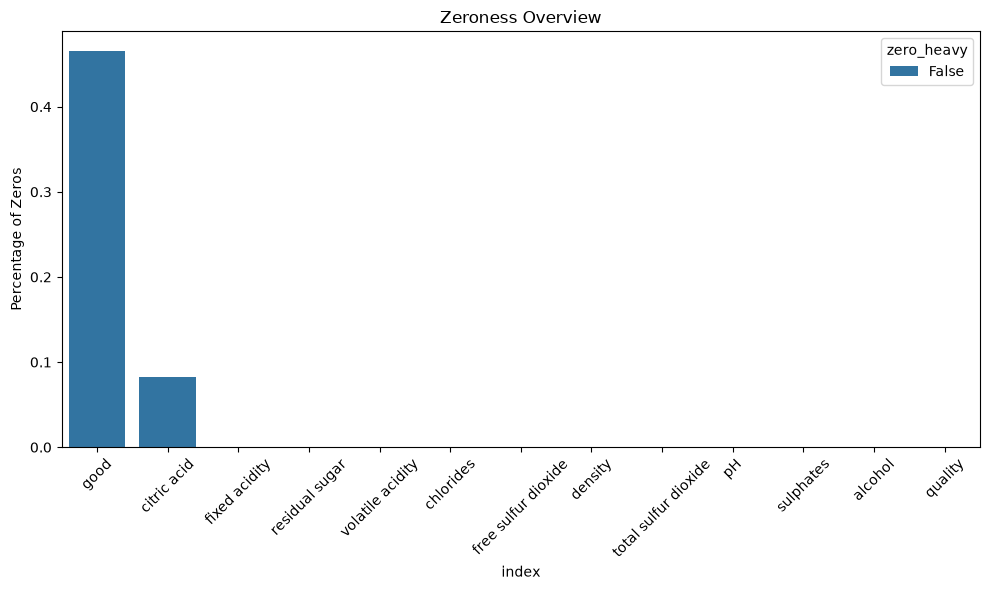

,zero_count,zero_pct,zero_heavy
good,744,0.465291,False
citric acid,132,0.082552,False
fixed acidity,0,0.000000,False
residual sugar,0,0.000000,False
volatile acidity,0,0.000000,False
chlorides,0,0.000000,False
free sulfur dioxide,0,0.000000,False
density,0,0.000000,False
total sulfur dioxide,0,0.000000,False
pH,0,0.000000,False


In [10]:
from src.visualization.eda import plot_zeroness

zero_stats = plot_zeroness(df)
zero_stats


## 6. Numeric feature distributions
Review for skewness, outliers and multimodality. Heavily skewed features
may benefit from log transformation in `build_features.py`.

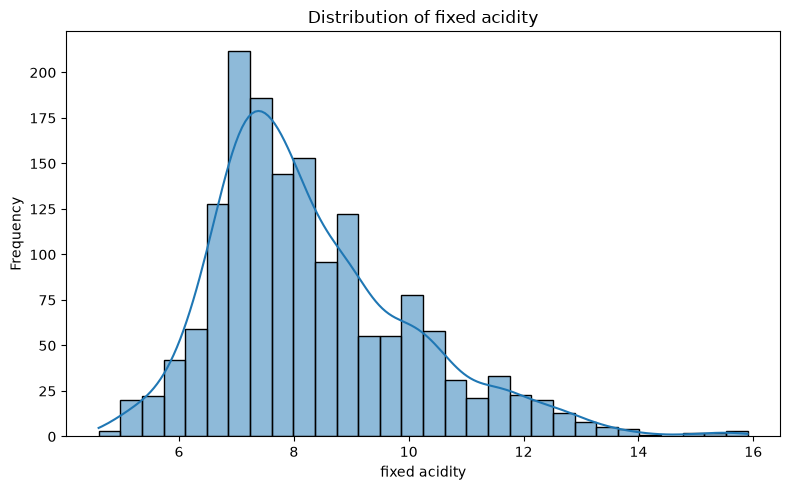

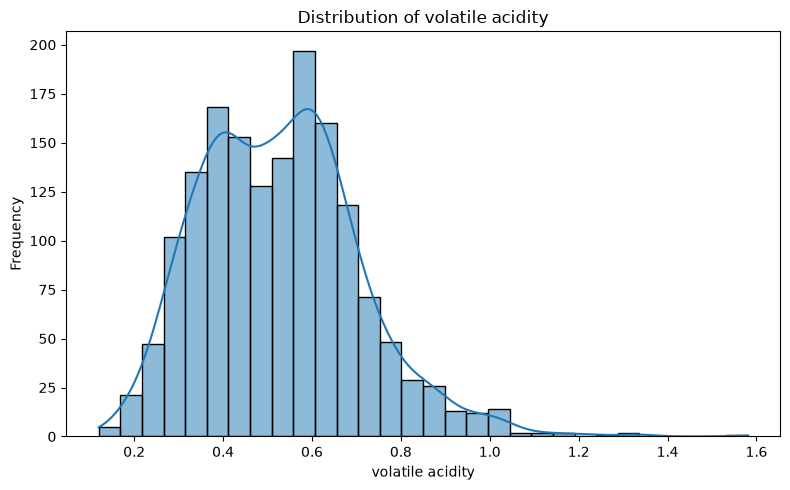

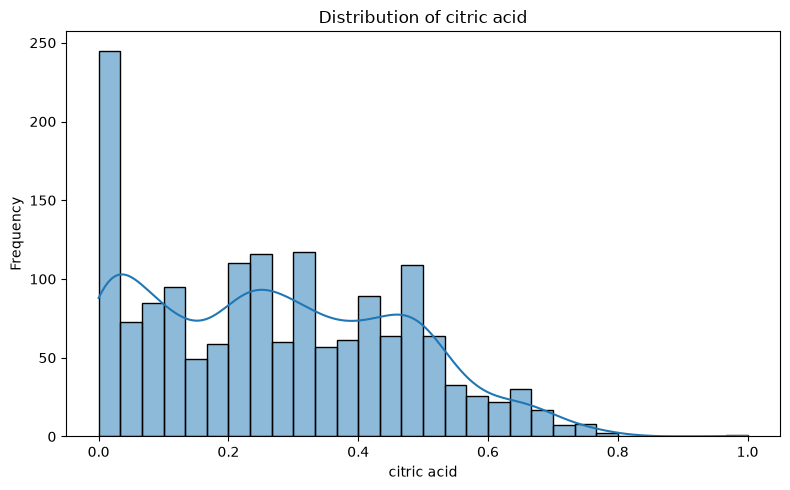

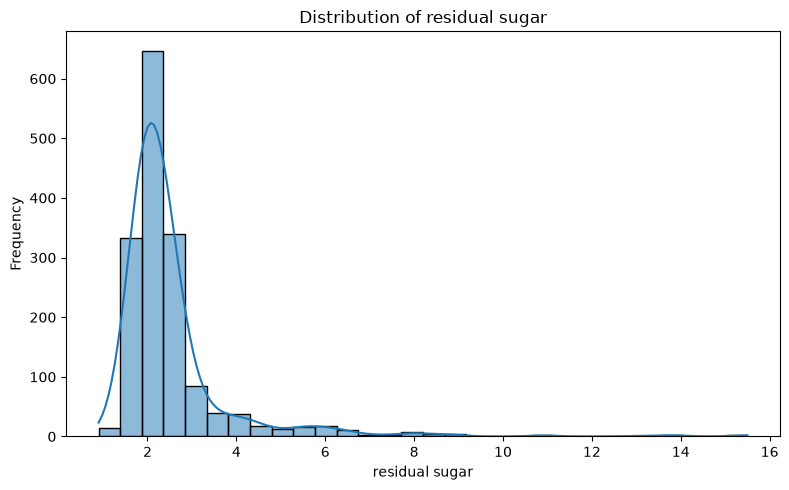

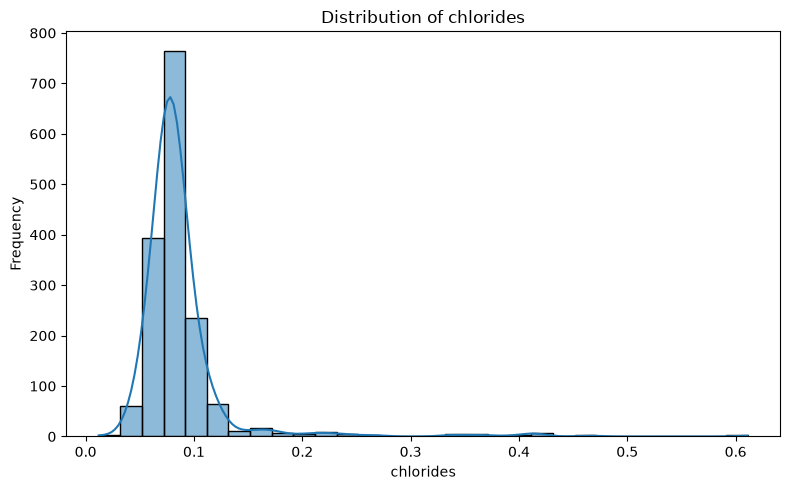

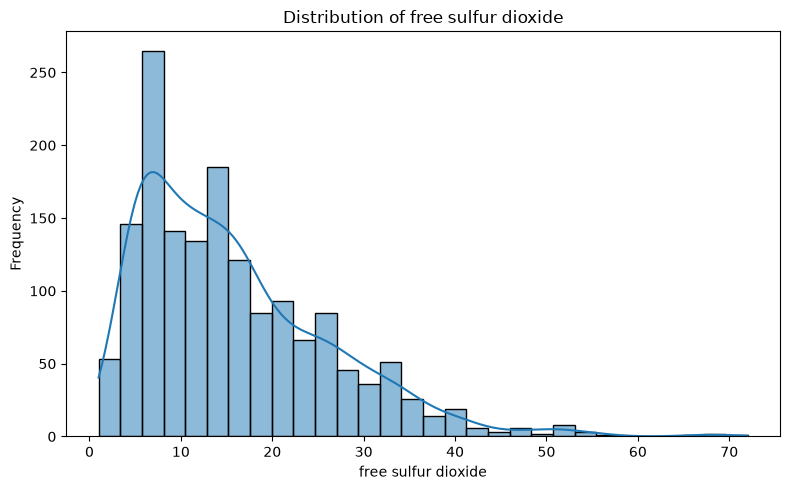

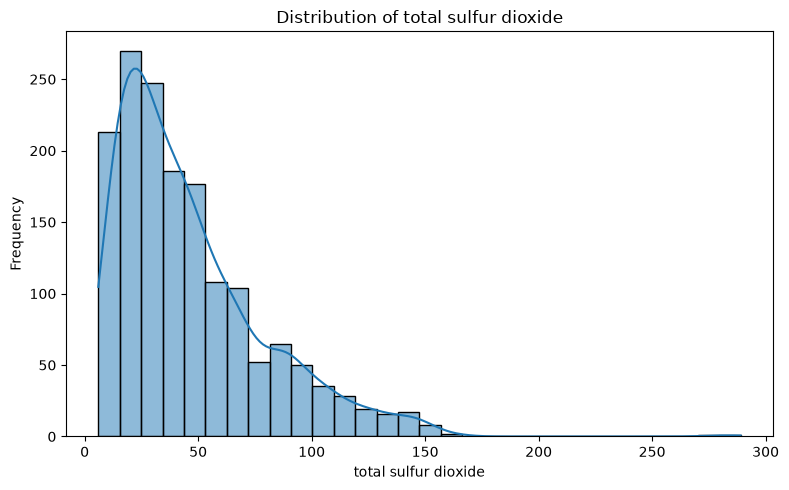

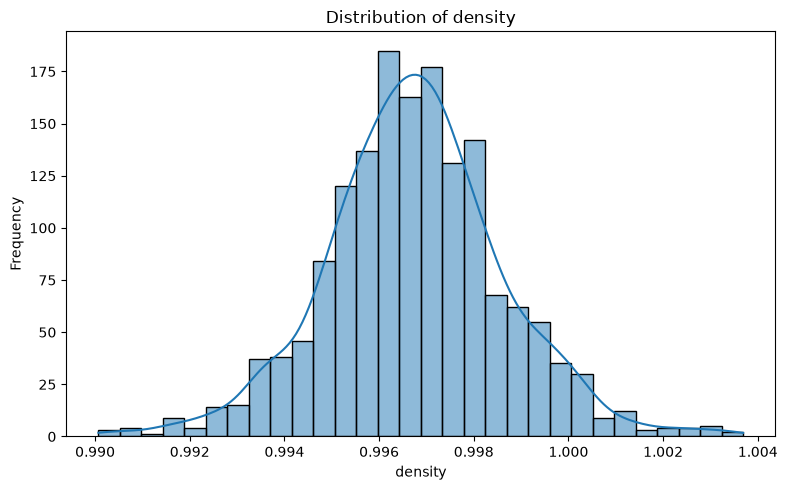

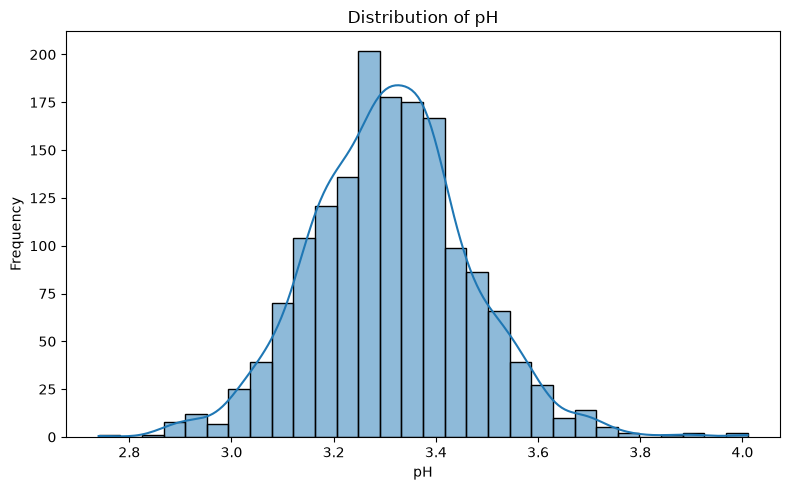

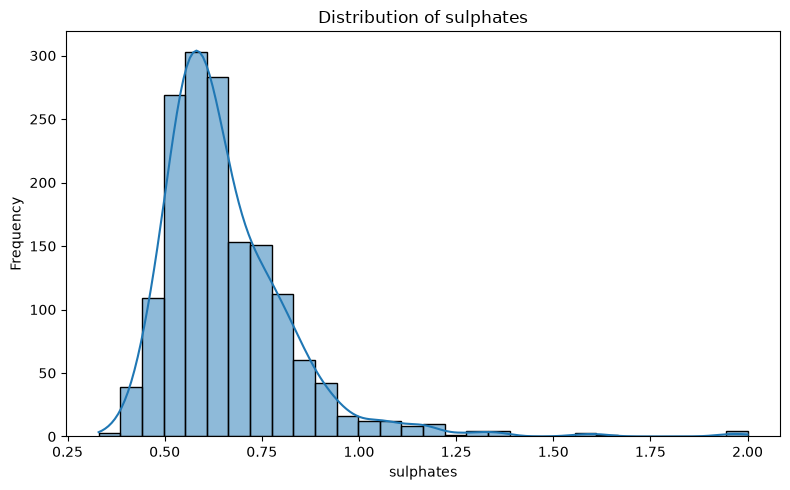

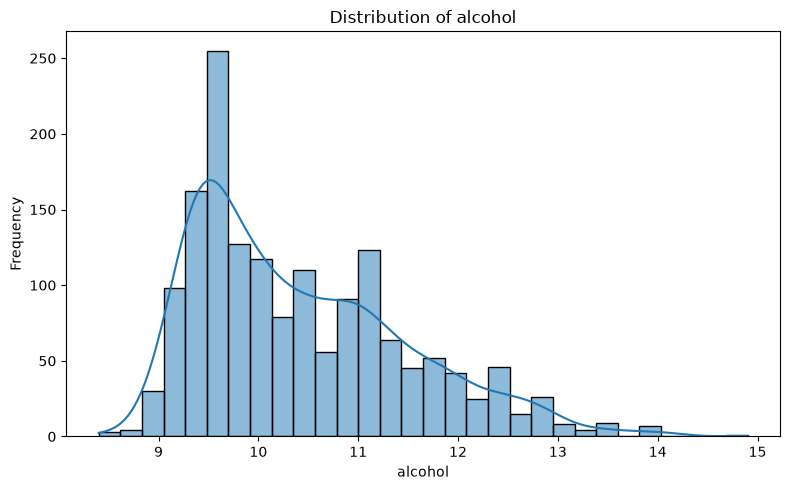

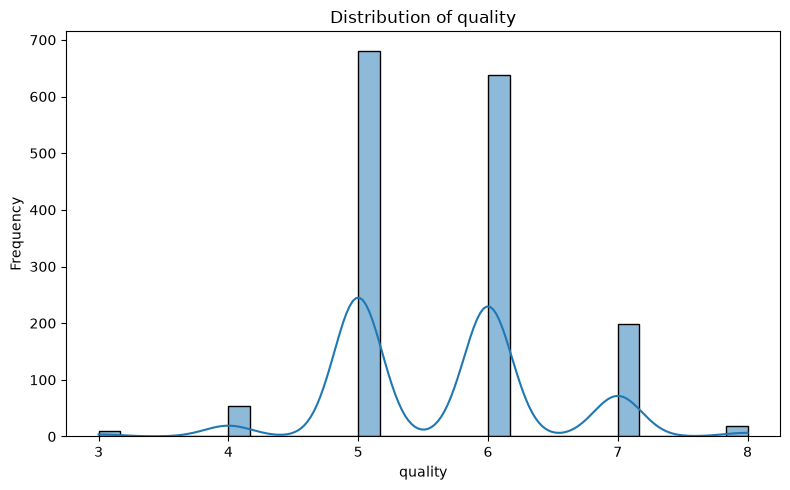

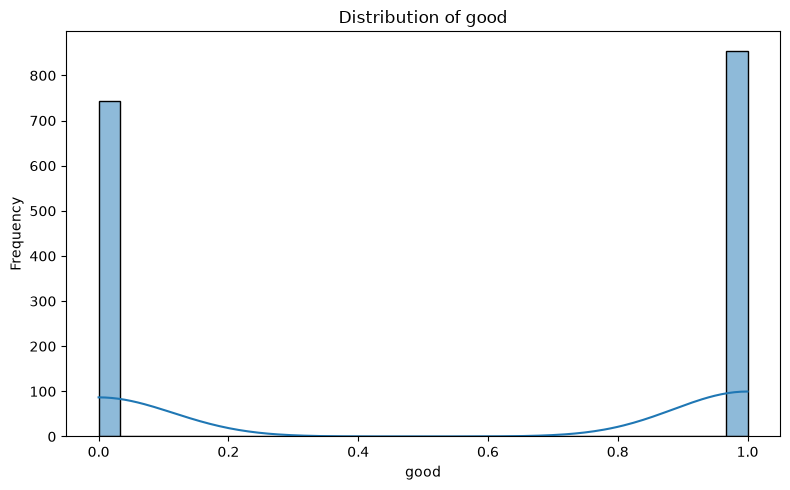

In [11]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

for col in numeric_cols:
    plot_numeric_distribution(df, col)


## 7. Categorical feature distributions
Review cardinality and class balance. High cardinality features will be
hash encoded by the pipeline — consider whether they carry useful signal.

In [12]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns

for col in categorical_cols:
    plot_categorical_distribution(df, col)


## 8. Target distribution
Confirm the problem type (classification vs regression) and check for
class imbalance. Severe imbalance may require stratified sampling or
class weighting — configure via `config.yaml`.

good
1    0.534709
0    0.465291
Name: proportion, dtype: float64

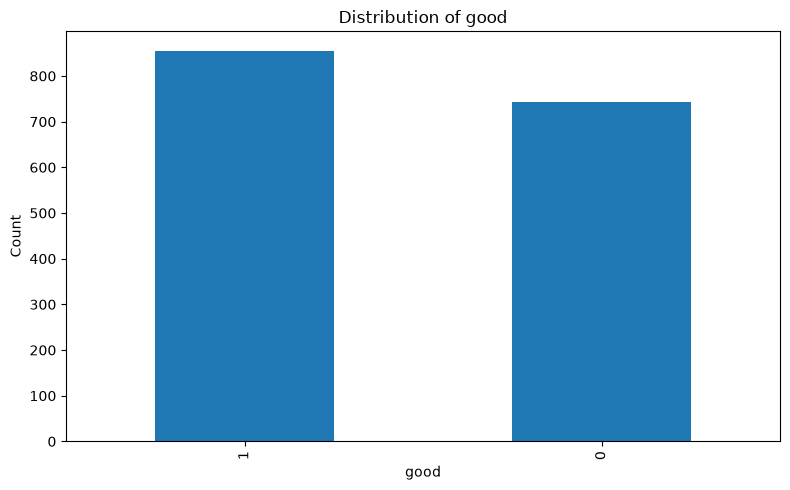

In [13]:
problem_type = detect_problem_type(df, TARGET)

if problem_type == "classification":
    display(df[TARGET].value_counts(normalize=True))
    plot_categorical_distribution(df, TARGET)
else:
    plot_numeric_target_distribution(df, TARGET)    




## 9. Feature-target relationships
Automatically plots the relationship between each feature and the target
using the appropriate chart type. Use these plots to identify strong
predictors for domain feature engineering in `build_features.py`.


🔍 Pairwise Feature–Target Analysis (classification)
Saving plots to: reports/figures/eda


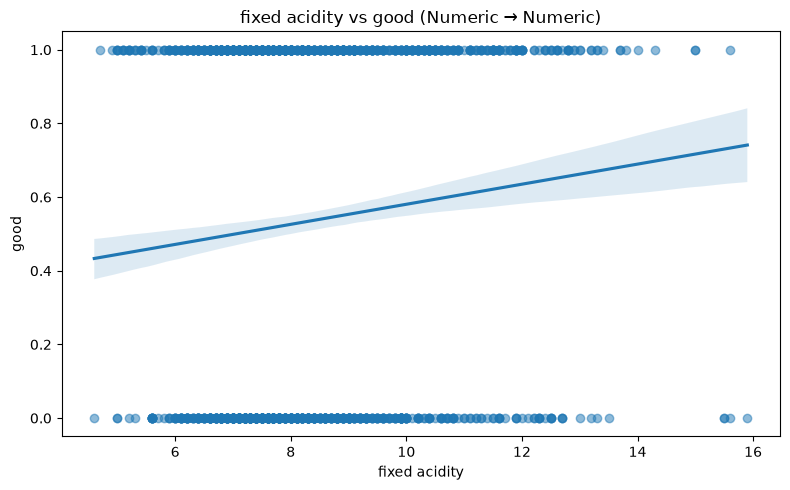

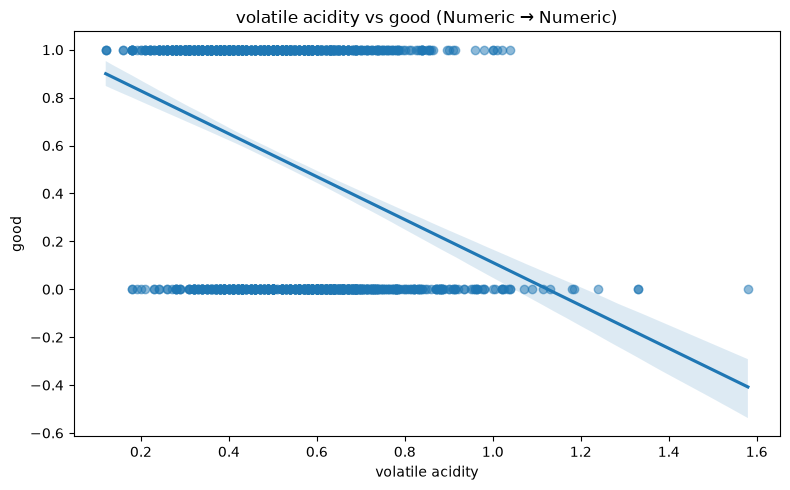

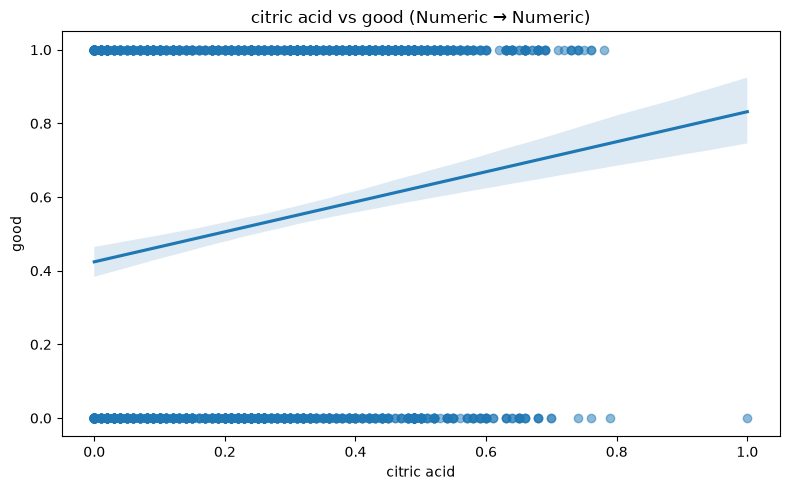

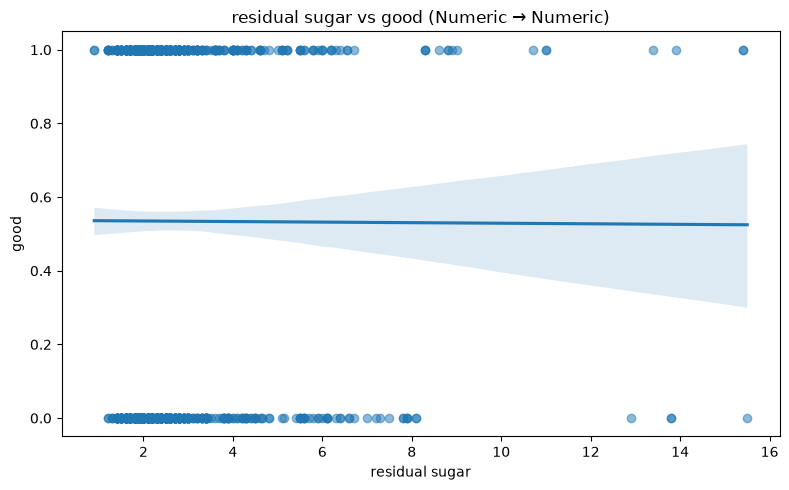

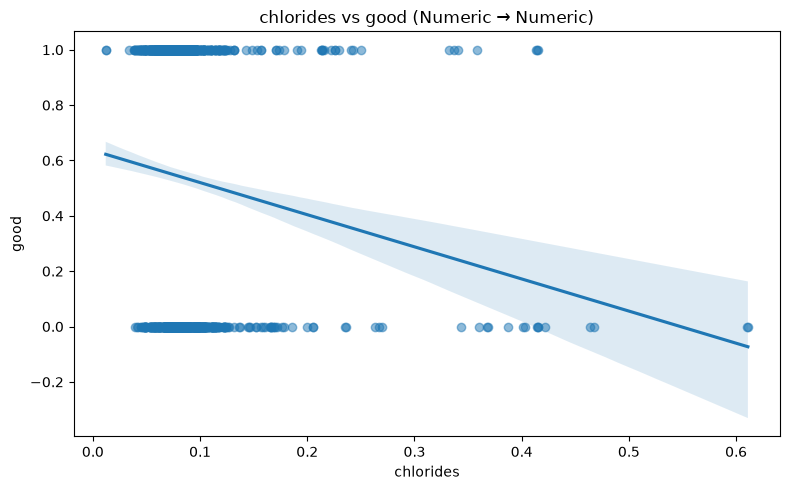

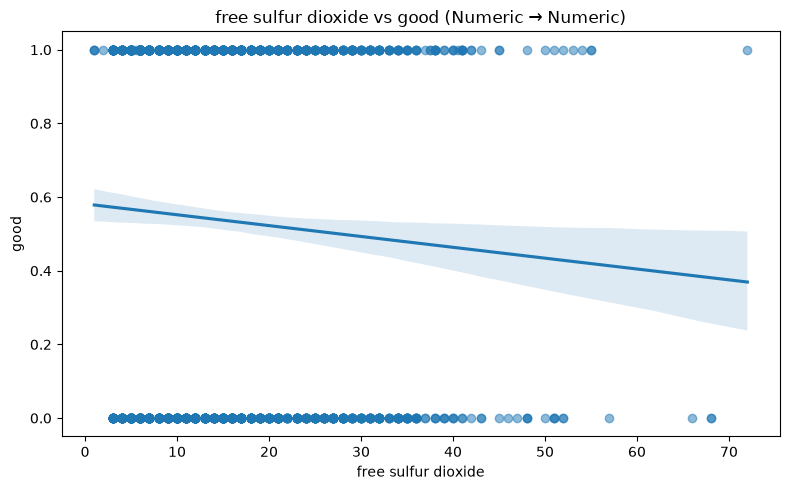

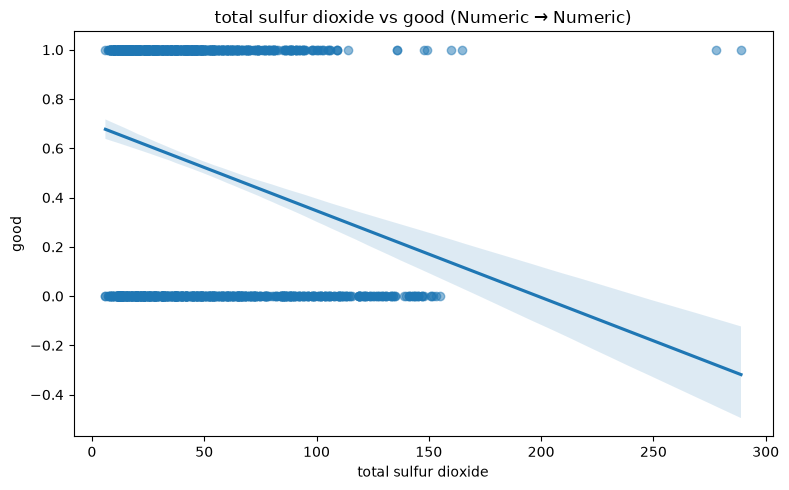

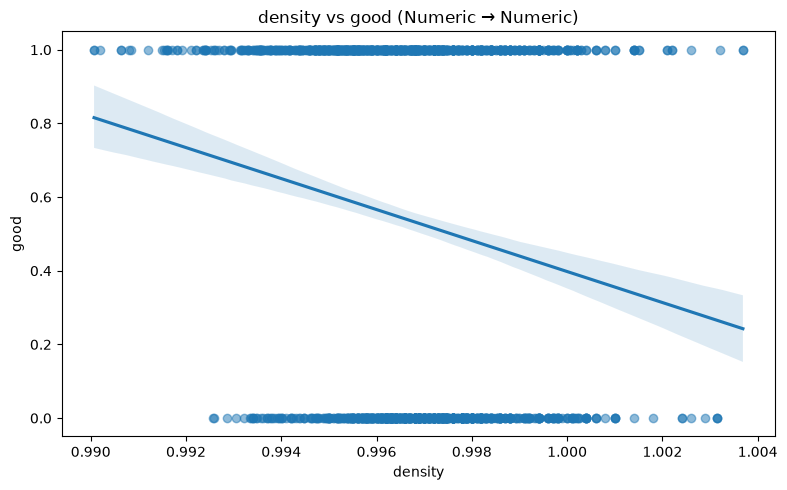

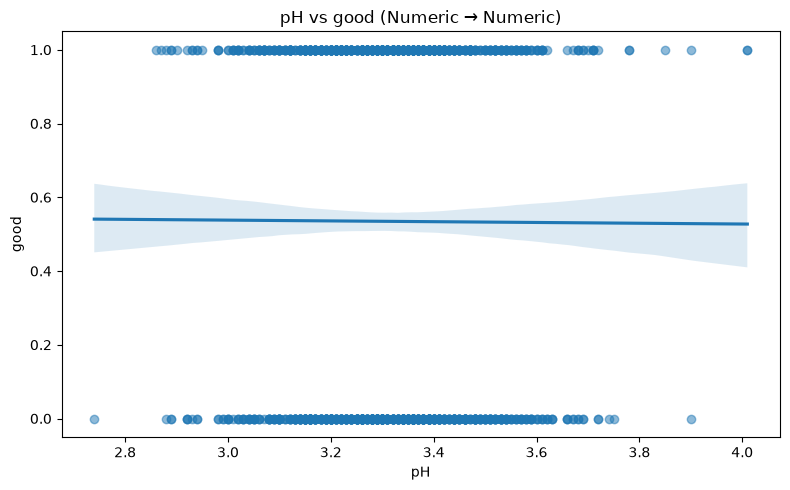

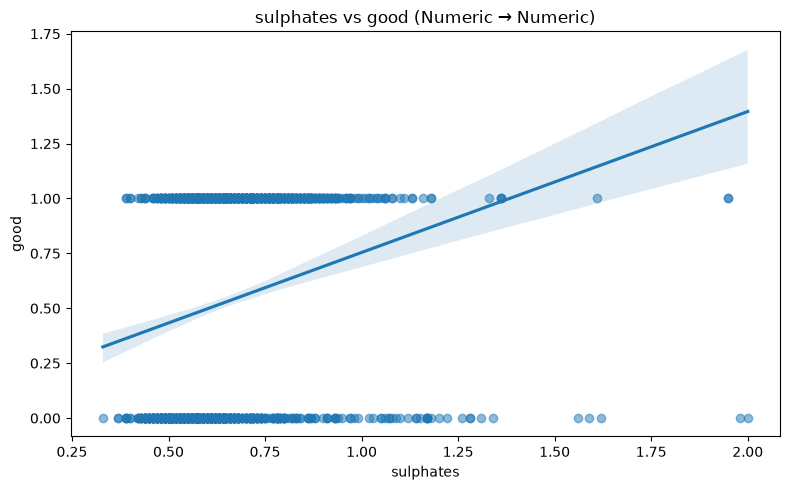

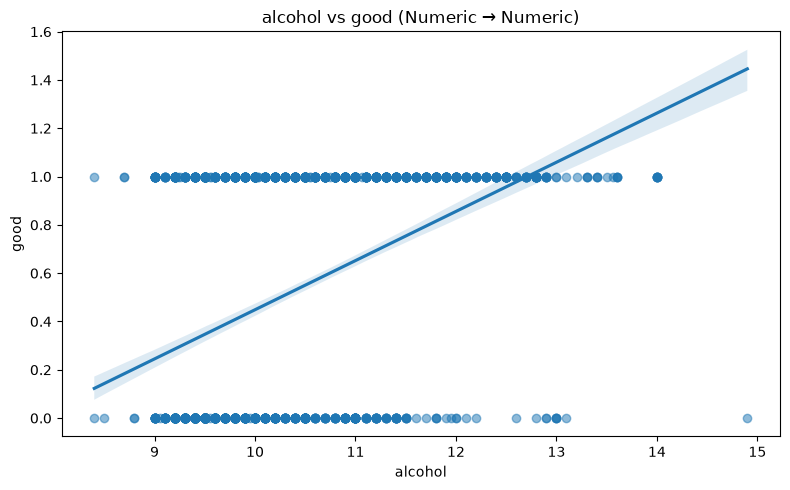

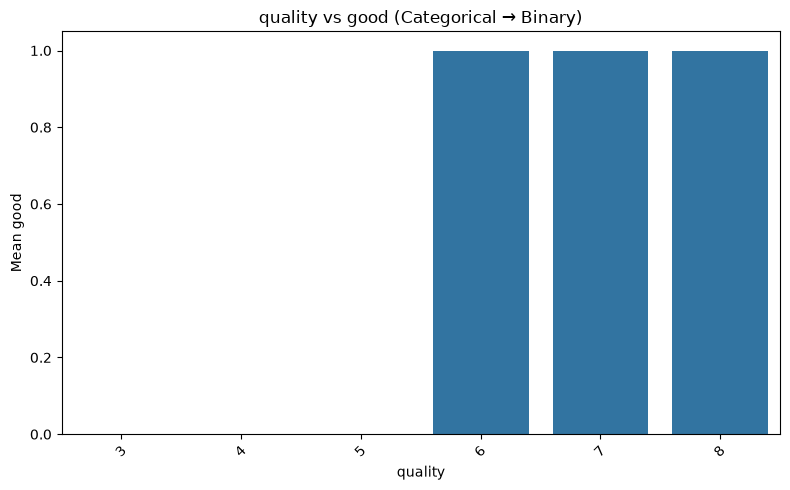

In [14]:
analyze_feature_target_relationships(df, TARGET)

## 10. Feature-feature interactions
Computes correlation, Cramér's V and mutual information between features.
Highly correlated feature pairs may be candidates for removal via
`correlation_threshold` in `config.yaml`.

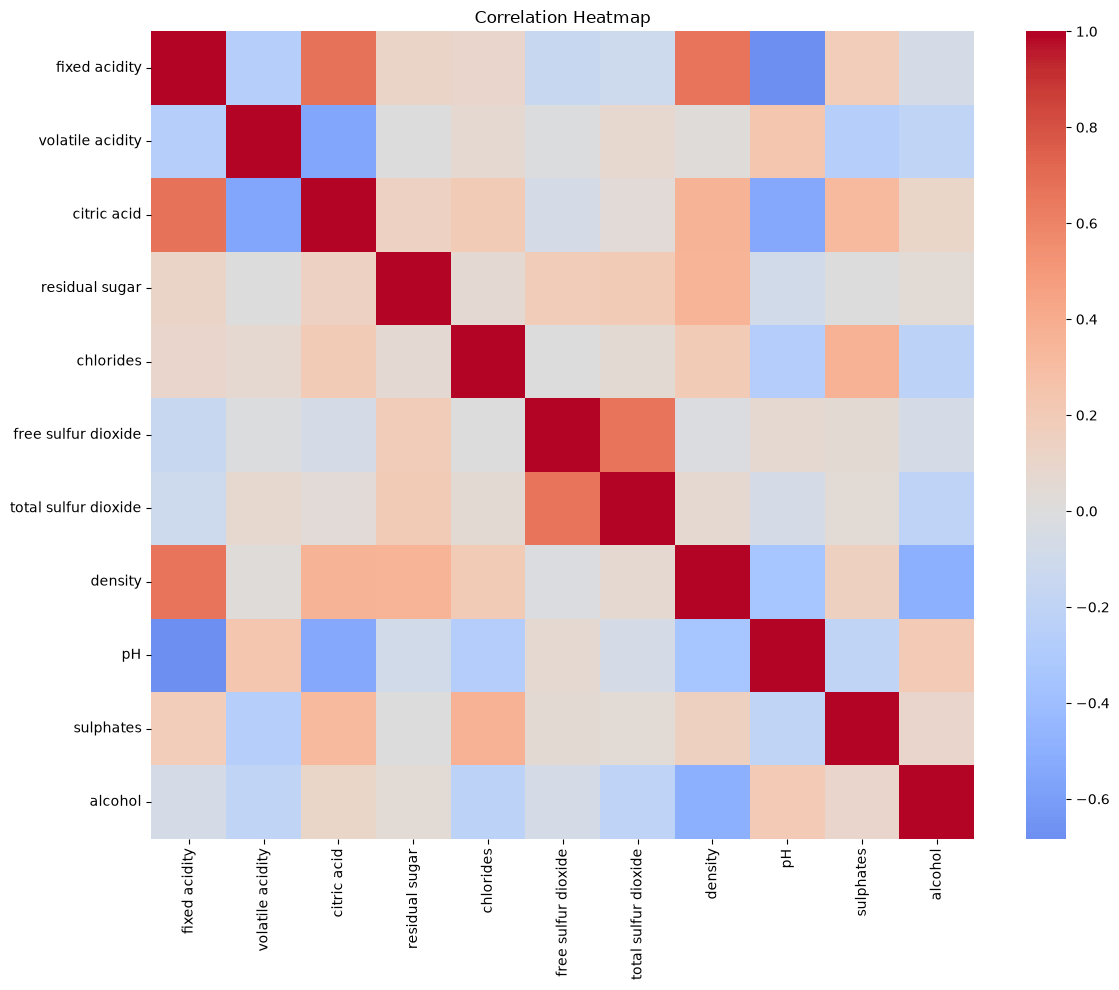

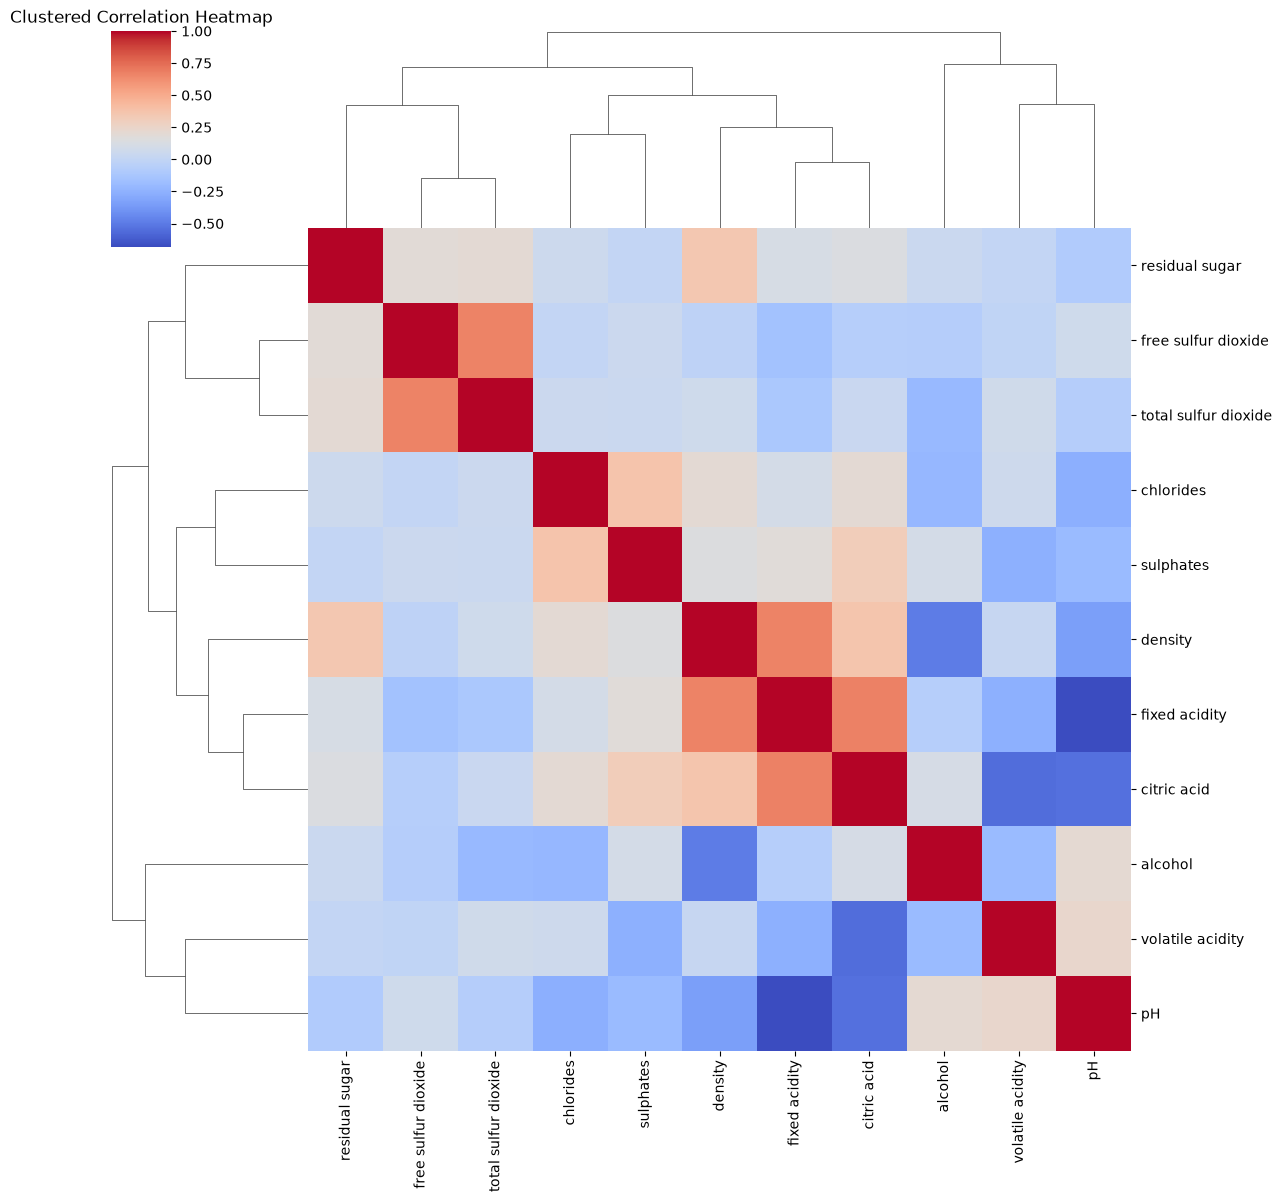

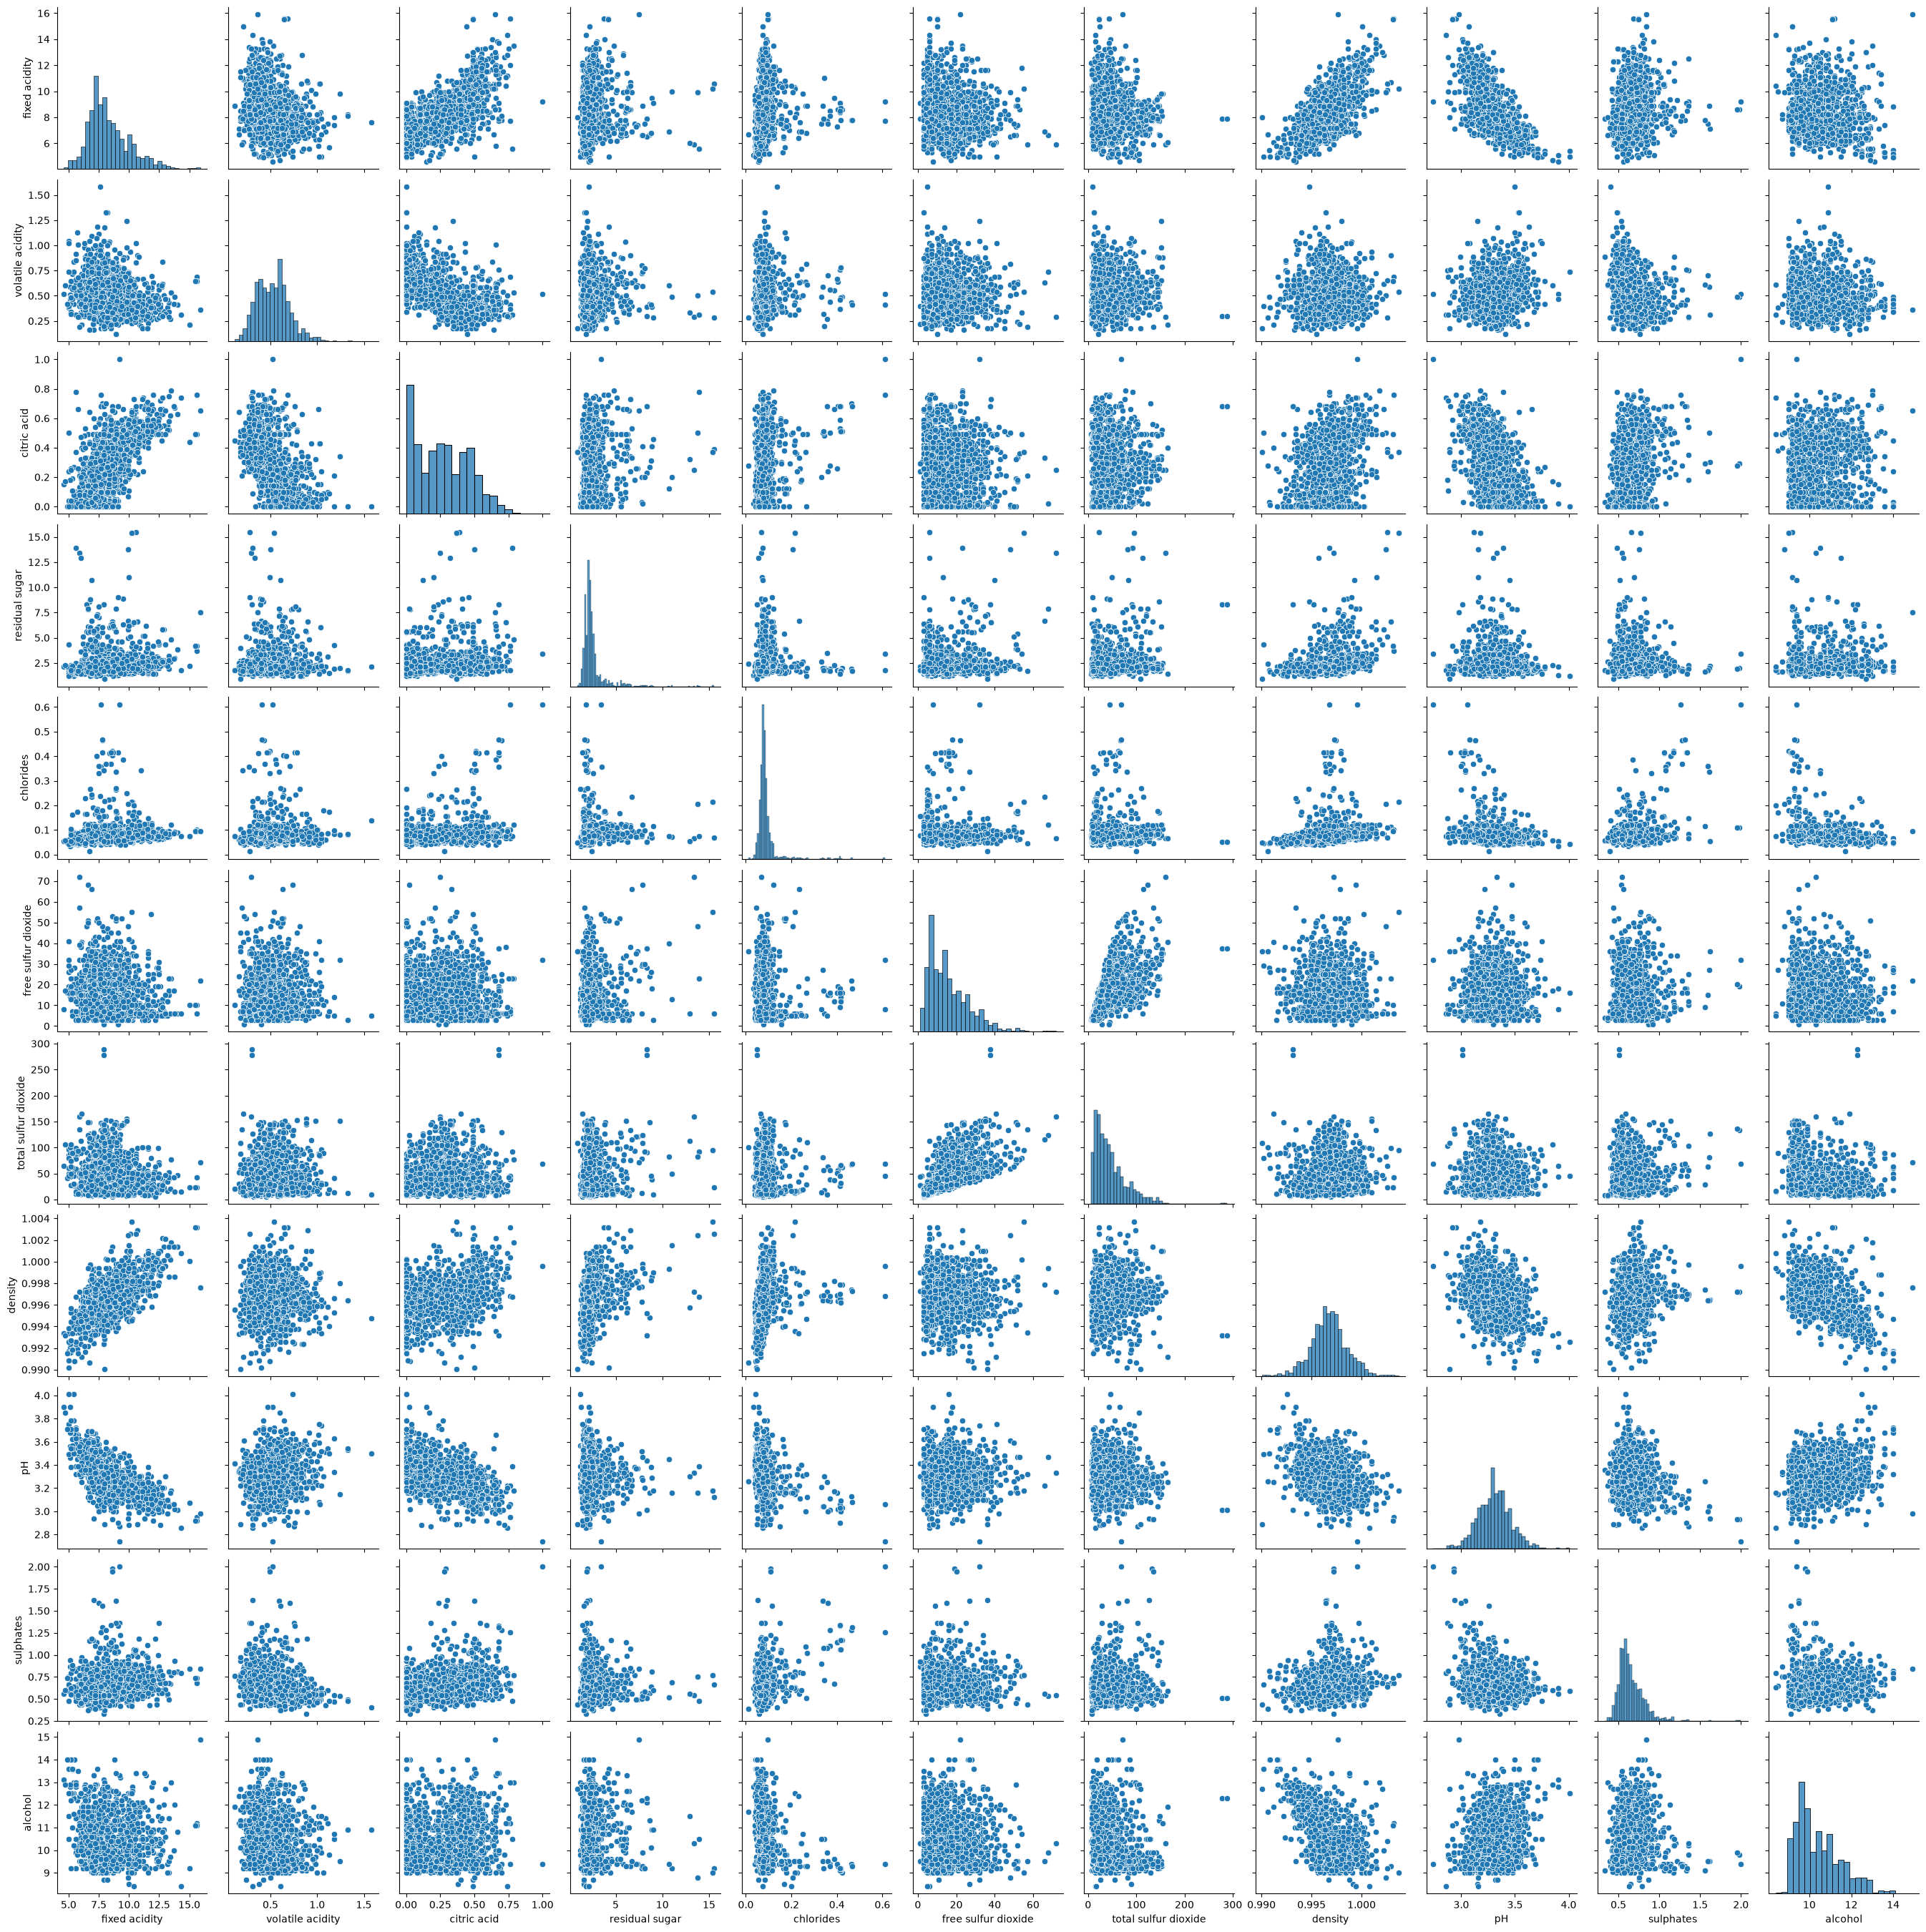

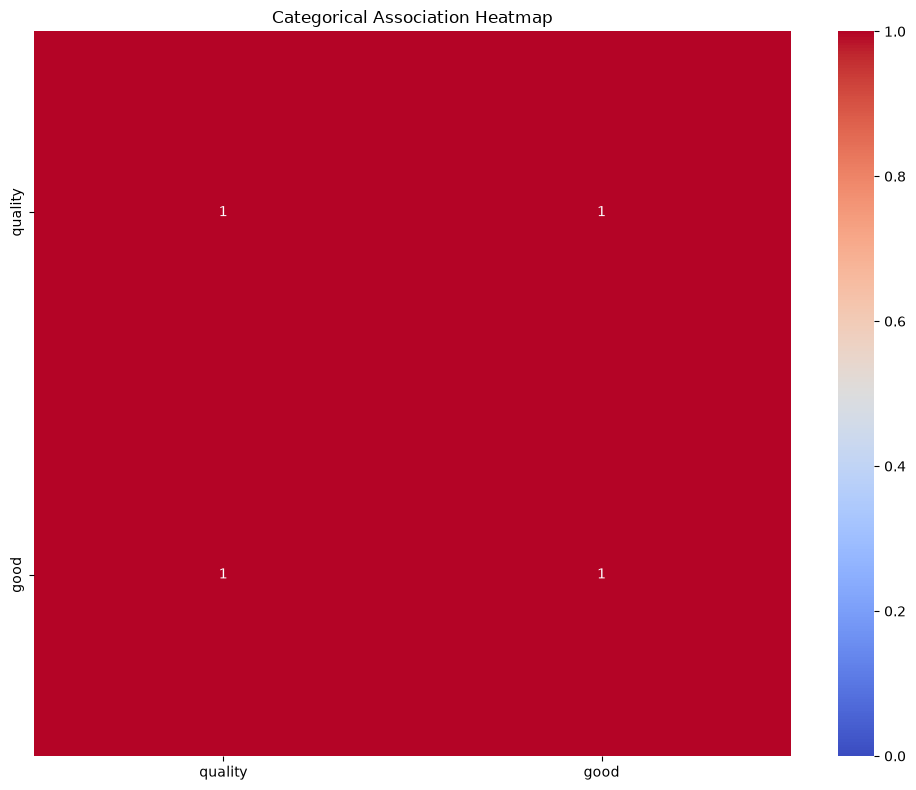

{'correlation_matrix':                       fixed acidity  volatile acidity  citric acid  \
 fixed acidity              1.000000         -0.256131     0.671703   
 volatile acidity          -0.256131          1.000000    -0.552496   
 citric acid                0.671703         -0.552496     1.000000   
 residual sugar             0.114777          0.001918     0.143577   
 chlorides                  0.093705          0.061298     0.203823   
 free sulfur dioxide       -0.153794         -0.010504    -0.060978   
 total sulfur dioxide      -0.113181          0.076470     0.035533   
 density                    0.668047          0.022026     0.364947   
 pH                        -0.682978          0.234937    -0.541904   
 sulphates                  0.183006         -0.260987     0.312770   
 alcohol                   -0.061668         -0.202288     0.109903   
 
                       residual sugar  chlorides  free sulfur dioxide  \
 fixed acidity               0.114777   0.093705   

In [15]:
feature_feature_results = analyze_feature_feature_relationships(df)

feature_feature_results


In [16]:
df.duplicated().sum() 

np.int64(240)

In [23]:
df.head(20)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,good
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
5,7.4,0.660,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0
6,7.9,0.600,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5,0
7,7.3,0.650,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7,1
8,7.8,0.580,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7,1
9,7.5,0.500,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5,0


460 rows in 220 duplicate groups, all with consistent quality, so treated as repeated entries and dropped before splitting

In [25]:
df_dedup = df.drop_duplicates(subset=feature_cols)
print(df_dedup.shape)
print(df_dedup["good"].value_counts())

(1359, 13)
good
1    719
0    640
Name: count, dtype: int64


In [26]:
df.drop(columns=["quality"]).corr()["good"].sort_values()

volatile acidity       -0.321441
total sulfur dioxide   -0.231963
density                -0.159110
chlorides              -0.109494
free sulfur dioxide    -0.061757
pH                     -0.003264
residual sugar         -0.002160
fixed acidity           0.095093
citric acid             0.159129
sulphates               0.218072
alcohol                 0.434751
good                    1.000000
Name: good, dtype: float64